In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df = pd.read_csv(r"C:\Users\Thesiya M\Downloads\EDA WEEK-7\StudentsPerformance.csv")

In [38]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [39]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [40]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [42]:
df.shape

(1000, 8)

In [43]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [44]:
df.isnull().sum().sum()

np.int64(0)

In [45]:
df.duplicated().sum()

np.int64(0)

In [46]:
df = df.drop_duplicates()

In [47]:
df.columns = df.columns.str.strip()

In [48]:
df["gender"] = df["gender"].str.strip().str.title()

In [49]:
df["race/ethnicity"] = df["race/ethnicity"].str.strip()

In [50]:
df["parental level of education"] = df["parental level of education"].str.strip()

In [51]:
df["lunch"] = df["lunch"].str.strip().str.title()

In [52]:
df["test preparation course"] = df["test preparation course"].str.strip().str.title()

In [53]:
df[["math score", "reading score", "writing score"]].mean()

math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

In [54]:
df[["math score", "reading score", "writing score"]].median()

math score       66.0
reading score    70.0
writing score    69.0
dtype: float64

In [55]:
df[["math score", "reading score", "writing score"]].std()

math score       15.163080
reading score    14.600192
writing score    15.195657
dtype: float64

In [56]:
df[["math score", "reading score", "writing score"]].min()

math score        0
reading score    17
writing score    10
dtype: int64

In [57]:
df[["math score", "reading score", "writing score"]].max()


math score       100
reading score    100
writing score    100
dtype: int64

In [58]:
df[["math score", "reading score", "writing score"]].quantile([0.25, 0.50, 0.75])

,math score,reading score,writing score
0.25,57.0,59.0,57.75
0.50,66.0,70.0,69.00
0.75,77.0,79.0,79.00


In [59]:
df["Total Marks"] = df["math score"] + df["reading score"] + df["writing score"]


In [60]:
df[["math score", "reading score", "writing score", "Total Marks"]]

,math score,reading score,writing score,Total Marks
0,72,72,74,218
1,69,90,88,247
2,90,95,93,278
3,47,57,44,148
4,76,78,75,229
...,...,...,...,...
995,88,99,95,282
996,62,55,55,172
997,59,71,65,195
998,68,78,77,223


In [61]:
df["Percentage"] = df["Total Marks"] / 3

df[["Total Marks", "Percentage"]]

,Total Marks,Percentage
0,218,72.666667
1,247,82.333333
2,278,92.666667
3,148,49.333333
4,229,76.333333
...,...,...
995,282,94.000000
996,172,57.333333
997,195,65.000000
998,223,74.333333


In [62]:
Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)
IQR = Q3 - Q1
Lower_Limit = Q1 - 1.5 * IQR
Upper_Limit = Q3 + 1.5 * IQR

Math_Outliers = df[(df["math score"] < Lower_Limit) | (df["math score"] > Upper_Limit)]

Math_Outliers

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks,Percentage
17,Female,group B,some high school,Free/Reduced,None,18,32,28,78,26.000000
59,Female,group C,some high school,Free/Reduced,None,0,17,10,27,9.000000
145,Female,group C,some college,Free/Reduced,None,22,39,33,94,31.333333
338,Female,group B,some high school,Free/Reduced,None,24,38,27,89,29.666667
466,Female,group D,associate's degree,Free/Reduced,None,26,31,38,95,31.666667
787,Female,group B,some college,Standard,None,19,38,32,89,29.666667
842,Female,group B,high school,Free/Reduced,Completed,23,44,36,103,34.333333
980,Female,group B,high school,Free/Reduced,None,8,24,23,55,18.333333


In [63]:
Q1 = df["reading score"].quantile(0.25)
Q3 = df["reading score"].quantile(0.75)
IQR = Q3 - Q1
Lower_Limit = Q1 - 1.5 * IQR
Upper_Limit = Q3 + 1.5 * IQR

Reading_Outliers = df[(df["reading score"] < Lower_Limit) | (df["reading score"] > Upper_Limit)]

Reading_Outliers

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks,Percentage
59,Female,group C,some high school,Free/Reduced,None,0,17,10,27,9.000000
76,Male,group E,some high school,Standard,None,30,26,22,78,26.000000
211,Male,group C,some college,Free/Reduced,None,35,28,27,90,30.000000
327,Male,group A,some college,Free/Reduced,None,28,23,19,70,23.333333
596,Male,group B,high school,Free/Reduced,None,30,24,15,69,23.000000
980,Female,group B,high school,Free/Reduced,None,8,24,23,55,18.333333


In [64]:
Q1 = df["writing score"].quantile(0.25)
Q3 = df["writing score"].quantile(0.75)
IQR = Q3 - Q1
Lower_Limit = Q1 - 1.5 * IQR
Upper_Limit = Q3 + 1.5 * IQR

Writing_Outliers = df[(df["writing score"] < Lower_Limit) | (df["writing score"] > Upper_Limit)]

Writing_Outliers

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks,Percentage
59,Female,group C,some high school,Free/Reduced,None,0,17,10,27,9.000000
76,Male,group E,some high school,Standard,None,30,26,22,78,26.000000
327,Male,group A,some college,Free/Reduced,None,28,23,19,70,23.333333
596,Male,group B,high school,Free/Reduced,None,30,24,15,69,23.000000
980,Female,group B,high school,Free/Reduced,None,8,24,23,55,18.333333


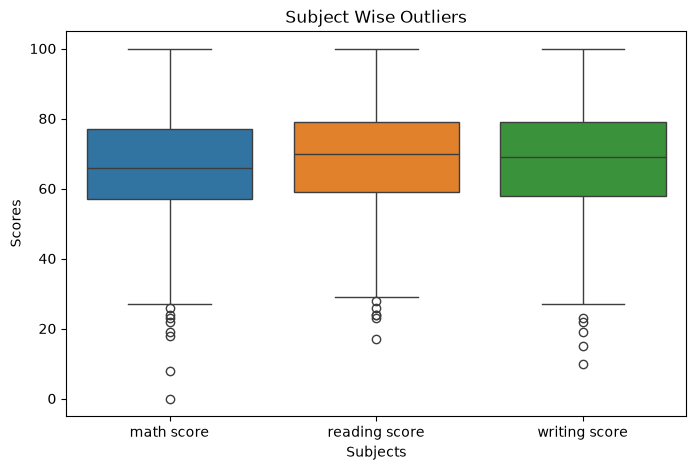

In [67]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df[["math score", "reading score", "writing score"]])
plt.title("Subject Wise Outliers")
plt.xlabel("Subjects")
plt.ylabel("Scores")
plt.show()

In [68]:
print("1. The dataset contains student performance records.")
print("2. Math, Reading and Writing scores are used for analysis.")
print("3. Mean and Median help to understand average student performance.")
print("4. Total Marks and Percentage help to evaluate overall performance.")
print("5. IQR method helps to identify outliers in subject scores.")

1. The dataset contains student performance records.
2. Math, Reading and Writing scores are used for analysis.
3. Mean and Median help to understand average student performance.
4. Total Marks and Percentage help to evaluate overall performance.
5. IQR method helps to identify outliers in subject scores.


In [69]:
df.to_csv("Cleaned_StudentsPerformance.csv", index=False)